In [1]:
"""ROC 1 - eff_bg vs eff_sig a partir de las salidas de `salt test`."""

from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

N señal = 56,034  N fondo = 59,687  AUC = 0.8661
  eff_sig = 60% -> 1-eff_bg = 0.9015  (corte p_sig > 0.7084)
  eff_sig = 70% -> 1-eff_bg = 0.8429  (corte p_sig > 0.6183)
  eff_sig = 80% -> 1-eff_bg = 0.7556  (corte p_sig > 0.5102)
  eff_sig = 90% -> 1-eff_bg = 0.6085  (corte p_sig > 0.3652)


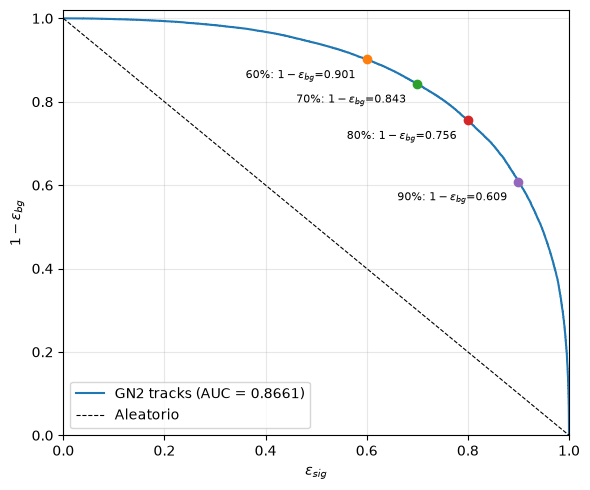

In [2]:
# --- Ajustar ---
OUT_TRAINING_PATH = Path('/home/usuario/VSCode/diHiggs-Project/OutTrainings/GN2Tracks_KGC_HadLep_20261125-T112854/')
EPOCH = "049"
OBJ = "jets"  # global_object del entrenamiento
SIG_CLASS = "hadtaujets"  # el score se llama <modelo>_p<clase>
WPS = [0.6, 0.7, 0.8, 0.9]  # working points a marcar (eficiencia de señal)


trapezoid = getattr(np, "trapezoid", None) or np.trapz  # numpy < 2.0


def find_test_file(sample):
    matches = sorted((OUT_TRAINING_PATH / "ckpts").glob(f"epoch={EPOCH}-*__test_{sample}*.h5"))
    if not matches:
        raise FileNotFoundError(f"No hay test '{sample}' para epoch={EPOCH} en {OUT_TRAINING_PATH / 'ckpts'}")
    return matches[0]


def load(fname):
    with h5py.File(fname, "r") as h:
        d = h[OBJ]
        score = next((n for n in d.dtype.names if n.endswith(f"_p{SIG_CLASS}")), None)
        if score is None:
            raise KeyError(f"No hay '*_p{SIG_CLASS}' en {fname.name}. Campos: {d.dtype.names}")
        return d.fields(score)[:].astype(np.float64)


s_sig = load(find_test_file("signal"))
s_bkg = load(find_test_file("background"))

# ROC: ordenar todos los scores de mayor a menor y acumular
scores = np.concatenate([s_sig, s_bkg])
is_sig = np.concatenate([np.ones_like(s_sig), np.zeros_like(s_bkg)])
order = np.argsort(-scores, kind="stable")
eff_sig = np.concatenate([[0], np.cumsum(is_sig[order]) / len(s_sig)])
eff_bkg = np.concatenate([[0], np.cumsum(1 - is_sig[order]) / len(s_bkg)])
auc = trapezoid(1 - eff_bkg, eff_sig)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(eff_sig, 1 - eff_bkg, label=f"GN2 tracks (AUC = {auc:.4f})")
ax.plot([0, 1], [1, 0], "k--", lw=0.8, label="Aleatorio")

print(f"N señal = {len(s_sig):,}  N fondo = {len(s_bkg):,}  AUC = {auc:.4f}")
for wp in WPS:
    cut = np.percentile(s_sig, 100 * (1 - wp))
    eb = np.mean(s_bkg > cut)
    print(f"  eff_sig = {wp:.0%} -> 1-eff_bg = {1 - eb:.4f}  (corte p_sig > {cut:.4f})")
    ax.plot(wp, 1 - eb, "o")
    ax.annotate(f"{wp:.0%}: $1-\\epsilon_{{bg}}$={1 - eb:.3f}", (wp, 1 - eb),
                textcoords="offset points", xytext=(-8, -14), ha="right", fontsize=8)

ax.set_xlabel(r"$\epsilon_{sig}$")
ax.set_ylabel(r"$1 - \epsilon_{bg}$")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(f'{OUT_TRAINING_PATH}/Roc.png', dpi=300)
plt.show()

In [ ]:
def Asimov(signal, bg, b_min=0.0):
    s = np.asarray(signal, dtype=float)
    b = np.asarray(bg,     dtype=float)

    valido = (b > b_min) & (s + b > 0)
    z = np.full(s.shape, np.nan)

    with np.errstate(divide="ignore", invalid="ignore"):
        s_v, b_v = s[valido], b[valido]
        z[valido] = np.sqrt(-2.0 * ((s_v + b_v) * np.log(b_v / (s_v + b_v)) + s_v))

    return z


# ===== Parametros del calculo de significancia =====

# Luminosity

L = 3 # ab-1

# Branching Ratios:

BR_h_tata = 0.0672
BR_h_bb = 0.58
BR_t_Wb = 0.998
BR_W_eu = 0.21 # Probabilidad compartida de decaimiento a e o u

# XS

# Señal por calculo    85514.4               ab
# Señal por MG         0.006997 +- 1.871e-05 pb
# Fondo por MG         0.002926 +- 1.03e-05  pb

sigma_gg_hh_LQ =  85514.4     # ab
sigma_pp_tth_SM = 2926        # ab

MG_XS_SIG = 6997.0    # ab, matched, muestra YA decaida
MG_XS_BKG = 2926.0    # ab, matched, muestra YA decaida

# f_sig = 2 * BR_h_tata * BR_h_bb                 # dos Higgs: (bb,tautau) + (tautau,bb)

f_sig = 1
f_bkg = 1    

sigma_ef_sig = MG_XS_SIG  * f_sig
sigma_ef_bkg = sigma_pp_tth_SM * f_bkg

Ns = L * sigma_ef_sig * eff_sig
Nb = L * sigma_ef_bkg * eff_bkg

L_fb = L * 1000.0
sep  = "=" * 70

print(sep); print("  PARAMETROS DEL CALCULO DE SIGNIFICANCIA"); print(sep)
print(f"  Luminosidad integrada      L = {L:g} ab^-1   ({L_fb:,.0f} fb^-1)")
print()
print("  Branching ratios")
print(f"    BR(h -> tau+ tau-)         = {BR_h_tata:.4f}")
print(f"    BR(h -> b b~)              = {BR_h_bb:.4f}")
print(f"    BR(t -> W b)               = {BR_t_Wb:.4f}")
print(f"    BR(W -> l vl)              = {BR_W_eu:.4f}")
print()
print("  Señal:  gg -> hh,  h -> b b~,  h -> tau+ tau-")
print("  Fondo:  pp -> tt~h(j),  h -> tau+ tau-,  t -> W b, W -> l nu")
print()
print(sep)

# Plot

significancias = np.array(Asimov(Ns, Nb))

fig, ax = plt.subplots(figsize=(8, 5.5))

significancias = Asimov(Ns, Nb)
wps = eff_sig

i_max = np.nanargmax(significancias)
ax.plot(wps, significancias, lw=1.8, label="Asimov")
ax.plot(wps[i_max], significancias[i_max], "r*", ms=14, zorder=5)
ax.axvline(wps[i_max], color="r", ls="--", lw=1, alpha=0.6)

ax.set_xlabel(r"Working point ($\epsilon_{sig}$)")
ax.set_ylabel(r"Significance")
ax.grid(alpha=0.3)
ax.legend(loc="lower center")

fig.tight_layout()
fig.savefig(f"{OUT_TRAINING_PATH}Significancia_vs_WP.png", dpi=300)
plt.close()
